In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In [2]:
# Load Nike Sales dataset
df = pd.read_csv(
    '/kaggle/input/datasets/nayakganesh007/nike-sales-uncleaned-dataset/Nike_Sales_Uncleaned.csv'
)

# Display first 5 rows
nike = df.copy()
nike.head()

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.0,2024-07-09,Retail,Hyd,-112.53
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.0,NaN,Retail,Mumbai,3337.34
3,2003,Kids,Lifestyle,Blazer Mid,L,NaN,9673.57,NaN,0.0,04-10-2024,Online,Pune,3376.85
4,2004,Kids,Running,React Infinity,XL,NaN,NaN,NaN,0.0,2024/09/12,Retail,Delhi,187.89


## 3. Standardize Column Names

In [3]:
nike.columns = (
    nike.columns
    .str.strip()
    .str.replace(' ', '_')
)

print(nike.columns.tolist())

['Order_ID', 'Gender_Category', 'Product_Line', 'Product_Name', 'Size', 'Units_Sold', 'MRP', 'Discount_Applied', 'Revenue', 'Order_Date', 'Sales_Channel', 'Region', 'Profit']


## 4. Initial Cleaning: Blank Values and Duplicate Rows

In [4]:
# Replace empty strings and whitespace with NaN
nike = nike.replace(r'^\s*$', np.nan, regex=True)

# Check duplicates
print("Duplicate Records:", nike.duplicated().sum())

# Remove exact duplicate records
nike = nike.drop_duplicates().copy()

# Check missing values
missing = pd.DataFrame({
    'Missing_Values': nike.isnull().sum(),
    'Missing_Percentage': (nike.isnull().mean() * 100).round(2)
})

missing

Duplicate Records: 0


,Missing_Values,Missing_Percentage
Order_ID,0,0.00
Gender_Category,0,0.00
Product_Line,0,0.00
Product_Name,0,0.00
Size,510,20.40
Units_Sold,1235,49.40
MRP,1254,50.16
Discount_Applied,1668,66.72
Revenue,0,0.00
Order_Date,616,24.64


## 5. Standardize Categorical Values

In [5]:
categorical_columns = [
    'Gender_Category',
    'Product_Line',
    'Product_Name',
    'Sales_Channel',
    'Region'
]

for col in categorical_columns:
    nike[col] = nike[col].str.strip().str.title()

## 6. Standardize Region Names

In [6]:
region_mapping = {
    'Bengaluru': 'Bangalore',
    'Bangalore': 'Bangalore',
    'Hyd': 'Hyderabad',
    'Hyderbad': 'Hyderabad',
    'Hyderabad': 'Hyderabad'
}

nike['Region'] = nike['Region'].replace(region_mapping)

nike['Region'].value_counts(dropna=False)

Region
Delhi        438
Bangalore    436
Mumbai       418
Kolkata      417
Hyderabad    403
Pune         388
Name: count, dtype: int64

## 7. Standardize Product Sizes

In [7]:
nike['Size'] = nike['Size'].astype('string').str.strip().str.upper()

print(nike['Size'].value_counts(dropna=False))

Size
L       513
XL      512
<NA>    510
M       478
7        86
11       77
10       76
9        68
12       61
8        60
6        59
Name: count, dtype: Int64


## 8. Convert Numeric Columns

In [8]:
numeric_columns = [
    'Units_Sold',
    'MRP',
    'Discount_Applied',
    'Revenue',
    'Profit'
]

for col in numeric_columns:
    nike[col] = pd.to_numeric(nike[col], errors='coerce')

nike[numeric_columns].dtypes

Units_Sold          float64
MRP                 float64
Discount_Applied    float64
Revenue             float64
Profit              float64
dtype: object

## 9. Validate Numeric Values

In [9]:
# Units sold cannot be zero or negative for a normal sales transaction
nike.loc[nike['Units_Sold'] <= 0, 'Units_Sold'] = np.nan

# MRP cannot be zero or negative
nike.loc[nike['MRP'] <= 0, 'MRP'] = np.nan

# Discount should be between 0 and 1
nike.loc[
    (nike['Discount_Applied'] < 0) |
    (nike['Discount_Applied'] > 1),
    'Discount_Applied'
] = np.nan

## 10. Check Missing Numeric Values

In [10]:
nike[numeric_columns].isnull().sum()

Units_Sold          1664
MRP                 1254
Discount_Applied    1848
Revenue                0
Profit                 0
dtype: int64

## 11. Convert Order Date

In [11]:
nike['Order_Date'] = pd.to_datetime(
    nike['Order_Date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

nike['Order_Date'].dtype

dtype('<M8[ns]')

## 12. Validate Order Dates

In [12]:
print("Missing Dates:", nike['Order_Date'].isnull().sum())

nike[['Order_ID', 'Order_Date']].head(10)

Missing Dates: 616


,Order_ID,Order_Date
0,2000,2024-03-09
1,2001,2024-07-09
2,2002,NaT
3,2003,2024-10-04
4,2004,2024-09-12
5,2005,NaT
6,2006,2025-06-04
7,2007,NaT
8,2008,2024-10-11
9,2009,NaT


## 13. Preserve Original Revenue and Calculate Revenue

`Calculated_Revenue` is calculated from `Units_Sold × MRP × (1 - Discount_Applied)`. The original revenue field is retained as `Original_Revenue` for comparison.

In [13]:
# Preserve original revenue
nike.rename(
    columns={'Revenue': 'Original_Revenue'},
    inplace=True
)

# Calculate revenue using available sales information
nike['Calculated_Revenue'] = (
    nike['Units_Sold'] *
    nike['MRP'] *
    (1 - nike['Discount_Applied'])
).round(2)

# Check calculated revenue
nike[['Original_Revenue', 'Calculated_Revenue']].head(10)

,Original_Revenue,Calculated_Revenue
0,0.0,NaN
1,0.0,NaN
2,0.0,NaN
3,0.0,NaN
4,0.0,NaN
5,0.0,NaN
6,0.0,NaN
7,0.0,NaN
8,0.0,NaN
9,0.0,NaN


### 14.1 Missing Values

In [14]:
# Missing values
nike.isnull().sum()

Order_ID                 0
Gender_Category          0
Product_Line             0
Product_Name             0
Size                   510
Units_Sold            1664
MRP                   1254
Discount_Applied      1848
Original_Revenue         0
Order_Date             616
Sales_Channel            0
Region                   0
Profit                   0
Calculated_Revenue    2390
dtype: int64

### 14.2 Duplicate Validation

In [15]:
# Duplicate records
print("Duplicates:", nike.duplicated().sum())

Duplicates: 0


### 14.3 Numerical Summary

In [16]:
# Numerical summary
nike.describe()

,Order_ID,Units_Sold,MRP,Discount_Applied,Original_Revenue,Order_Date,Profit,Calculated_Revenue
count,2500.000000,836.000000,1246.000000,652.000000,2500.000000,1884,2500.000000,110.000000
mean,3194.352400,2.488038,6039.863395,0.495752,274.873716,2024-11-24 19:37:50.063694336,1376.012848,7284.846818
min,2000.000000,1.000000,2006.630000,0.000000,-7561.590000,2023-07-26 00:00:00,-1199.450000,236.320000
25%,2534.750000,2.000000,4038.902500,0.240000,0.000000,2024-09-04 00:00:00,93.532500,3305.942500
50%,3192.500000,2.000000,6110.030000,0.490000,0.000000,2024-12-16 00:00:00,1371.385000,5591.790000
75%,3841.250000,4.000000,8022.187500,0.750000,0.000000,2025-04-05 00:00:00,2660.645000,9235.067500
max,4499.000000,4.000000,9996.220000,1.000000,37169.350000,2025-07-22 00:00:00,3999.210000,37169.350000
std,749.972638,1.115423,2315.746826,0.290349,2023.773550,NaN,1478.671013,6177.402691


### 14.4 Dataset Shape, Columns, and Information

In [17]:
print("Dataset Shape:", nike.shape)

print("\nColumn Names:")
print(nike.columns.tolist())

print("\nDataset Information:")
nike.info()

Dataset Shape: (2500, 14)

Column Names:
['Order_ID', 'Gender_Category', 'Product_Line', 'Product_Name', 'Size', 'Units_Sold', 'MRP', 'Discount_Applied', 'Original_Revenue', 'Order_Date', 'Sales_Channel', 'Region', 'Profit', 'Calculated_Revenue']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Order_ID            2500 non-null   int64         
 1   Gender_Category     2500 non-null   object        
 2   Product_Line        2500 non-null   object        
 3   Product_Name        2500 non-null   object        
 4   Size                1990 non-null   string        
 5   Units_Sold          836 non-null    float64       
 6   MRP                 1246 non-null   float64       
 7   Discount_Applied    652 non-null    float64       
 8   Original_Revenue    2500 non-null   float64       
 9   Ord

## 15. Export Cleaned Dataset

In [18]:
nike.to_csv(
    'Nike_Sales_Cleaned.csv',
    index=False
)

print("Nike Sales Dataset exported successfully!")

Nike Sales Dataset exported successfully!


## 16. Investigate Original Revenue Values

In [19]:
print("Revenue Analysis")

print("\nZero Revenue:")
print((nike['Original_Revenue'] == 0).sum())

print("\nPositive Revenue:")
print((nike['Original_Revenue'] > 0).sum())

print("\nNegative Revenue:")
print((nike['Original_Revenue'] < 0).sum())

print("\nRevenue Statistics:")
print(nike['Original_Revenue'].describe())

Revenue Analysis

Zero Revenue:
2334

Positive Revenue:
113

Negative Revenue:
53

Revenue Statistics:
count     2500.000000
mean       274.873716
std       2023.773550
min      -7561.590000
25%          0.000000
50%          0.000000
75%          0.000000
max      37169.350000
Name: Original_Revenue, dtype: float64


### 16.1 Inspect Negative Revenue Records

In [20]:
negative_revenue = nike[
    nike['Original_Revenue'] < 0
]

print("Negative Revenue Records:", len(negative_revenue))

negative_revenue[
    [
        'Order_ID',
        'Product_Name',
        'Units_Sold',
        'MRP',
        'Discount_Applied',
        'Original_Revenue',
        'Profit'
    ]
].head(15)

Negative Revenue Records: 53


,Order_ID,Product_Name,Units_Sold,MRP,Discount_Applied,Original_Revenue,Profit
21,2021,Free Rn,NaN,7086.70,0.66,-2409.48,-1120.49
37,2037,Pegasus Turbo,3.0,5653.14,NaN,-169.59,2776.96
234,2234,Flex Trainer,4.0,6189.10,NaN,-2970.77,2085.62
242,2046,Lebron 20,NaN,4934.46,0.86,-690.82,2237.95
264,2264,Zoomx Invincible,4.0,5622.32,NaN,-1799.14,1248.25
359,2359,Waffle One,NaN,9836.48,0.34,-6492.08,-874.96
381,2381,Dunk Low,3.0,4834.65,NaN,-290.08,213.96
384,2384,Superrep Go,3.0,2070.97,NaN,-1553.23,42.89
416,2416,Mercurial Superfly,3.0,6245.23,NaN,-2810.35,3485.64
434,2434,Metcon 7,NaN,3019.25,0.79,-634.04,387.15


## 17. Investigate Units Sold

In [21]:
print("Units Sold Distribution")

print("\nNegative Units Sold:")
print((nike['Units_Sold'] < 0).sum())

print("\nZero Units Sold:")
print((nike['Units_Sold'] == 0).sum())

print("\nPositive Units Sold:")
print((nike['Units_Sold'] > 0).sum())

print("\nMissing Units Sold:")
print(nike['Units_Sold'].isnull().sum())

Units Sold Distribution

Negative Units Sold:
0

Zero Units Sold:
0

Positive Units Sold:
836

Missing Units Sold:
1664


## 18. Missing-Value Analysis

In [22]:
numeric_columns = [
    'Units_Sold',
    'MRP',
    'Discount_Applied',
    'Original_Revenue',
    'Profit'
]

missing_analysis = pd.DataFrame({
    'Missing_Count': nike[numeric_columns].isnull().sum(),
    'Missing_Percentage': (
        nike[numeric_columns].isnull().mean() * 100
    ).round(2)
})

missing_analysis

,Missing_Count,Missing_Percentage
Units_Sold,1664,66.56
MRP,1254,50.16
Discount_Applied,1848,73.92
Original_Revenue,0,0.00
Profit,0,0.00


### 18.1 Missing-Value Patterns

In [23]:
missing_pattern = nike[
    ['Units_Sold', 'MRP', 'Discount_Applied']
].isnull()

print("Missing Values Combination:")

print(
    missing_pattern.value_counts()
    .rename("Record_Count")
)

Missing Values Combination:
Units_Sold  MRP    Discount_Applied
True        False  True                628
            True   True                614
False       False  True                310
            True   True                296
True        True   False               224
            False  False               198
False       True   False               120
            False  False               110
Name: Record_Count, dtype: int64


## 19. Investigate Discount Values

In [24]:
print("Discount Statistics:")
print(nike['Discount_Applied'].describe())

print("\nUnique Discount Values:")
print(
    sorted(
        nike['Discount_Applied']
        .dropna()
        .unique()
    )
)

Discount Statistics:
count    652.000000
mean       0.495752
std        0.290349
min        0.000000
25%        0.240000
50%        0.490000
75%        0.750000
max        1.000000
Name: Discount_Applied, dtype: float64

Unique Discount Values:
[np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07), np.float64(0.08), np.float64(0.09), np.float64(0.1), np.float64(0.11), np.float64(0.12), np.float64(0.13), np.float64(0.14), np.float64(0.15), np.float64(0.16), np.float64(0.17), np.float64(0.18), np.float64(0.19), np.float64(0.2), np.float64(0.21), np.float64(0.22), np.float64(0.23), np.float64(0.24), np.float64(0.25), np.float64(0.26), np.float64(0.27), np.float64(0.28), np.float64(0.29), np.float64(0.3), np.float64(0.31), np.float64(0.32), np.float64(0.33), np.float64(0.34), np.float64(0.35), np.float64(0.36), np.float64(0.37), np.float64(0.38), np.float64(0.39), np.float64(0.4), np.float64(0.41), np.

## 20. Investigate MRP Values

In [25]:
print("MRP Statistics:")
print(nike['MRP'].describe())

print("\nZero MRP:")
print((nike['MRP'] == 0).sum())

print("\nNegative MRP:")
print((nike['MRP'] < 0).sum())

print("\nPositive MRP:")
print((nike['MRP'] > 0).sum())

print("\nMissing MRP:")
print(nike['MRP'].isnull().sum())

MRP Statistics:
count    1246.000000
mean     6039.863395
std      2315.746826
min      2006.630000
25%      4038.902500
50%      6110.030000
75%      8022.187500
max      9996.220000
Name: MRP, dtype: float64

Zero MRP:
0

Negative MRP:
0

Positive MRP:
1246

Missing MRP:
1254


## 21. Investigate Profit Values

In [26]:
print("Profit Statistics:")
print(nike['Profit'].describe())

print("\nZero Profit:")
print((nike['Profit'] == 0).sum())

print("\nNegative Profit:")
print((nike['Profit'] < 0).sum())

print("\nPositive Profit:")
print((nike['Profit'] > 0).sum())

print("\nMissing Profit:")
print(nike['Profit'].isnull().sum())

Profit Statistics:
count    2500.000000
mean     1376.012848
std      1478.671013
min     -1199.450000
25%        93.532500
50%      1371.385000
75%      2660.645000
max      3999.210000
Name: Profit, dtype: float64

Zero Profit:
0

Negative Profit:
578

Positive Profit:
1922

Missing Profit:
0


### 21.2 Inspect Negative Profit Records

In [27]:
negative_profit = nike[nike['Profit'] < 0]

negative_profit.head(10)

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Original_Revenue,Order_Date,Sales_Channel,Region,Profit,Calculated_Revenue
0,2000,Kids,Training,Superrep Go,M,NaN,NaN,0.47,0.00,2024-03-09,Online,Bangalore,-770.45,NaN
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.00,2024-07-09,Retail,Hyderabad,-112.53,NaN
8,2008,Women,Soccer,Premier Iii,11,NaN,NaN,NaN,0.00,2024-10-11,Online,Hyderabad,-731.18,NaN
14,2014,Women,Running,React Infinity,11,NaN,NaN,NaN,0.00,2025-04-12,Online,Bangalore,-1044.40,NaN
18,2018,Men,Training,Metcon 7,XL,NaN,NaN,NaN,0.00,NaT,Online,Bangalore,-966.89,NaN
21,2021,Men,Running,Free Rn,L,NaN,7086.70,0.66,-2409.48,2024-11-19,Retail,Hyderabad,-1120.49,NaN
27,2027,Men,Basketball,Zoom Freak,XL,NaN,NaN,0.22,0.00,NaT,Online,Pune,-138.74,NaN
28,2028,Men,Training,Flex Trainer,12,NaN,3270.23,NaN,0.00,NaT,Retail,Delhi,-946.86,NaN
29,2029,Men,Training,Zoomx Invincible,12,NaN,NaN,NaN,0.00,2023-10-28,Online,Bangalore,-185.67,NaN
30,2030,Men,Soccer,Phantom Gt,XL,NaN,NaN,NaN,0.00,2025-07-14,Retail,Hyderabad,-122.93,NaN


# Exploratory Data Analysis (EDA)

The following sections explore the cleaned dataset. Use the outputs and charts to write short observations; do not treat unusual values as errors without validating them.

In [28]:
numeric_cols = nike.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_cols.tolist())

Numerical Columns:
['Order_ID', 'Units_Sold', 'MRP', 'Discount_Applied', 'Original_Revenue', 'Profit', 'Calculated_Revenue']


## Phase 1 – Understanding the Dataset

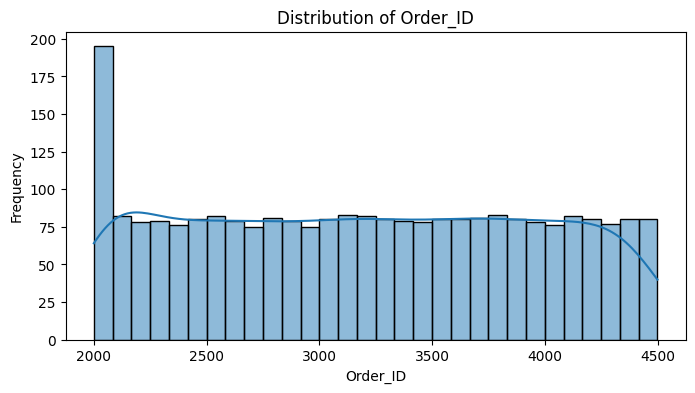

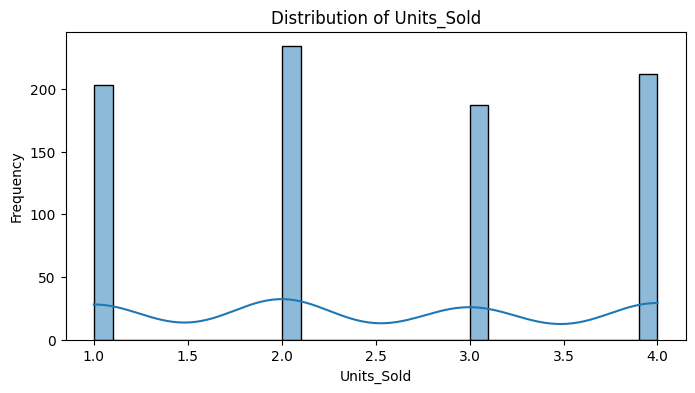

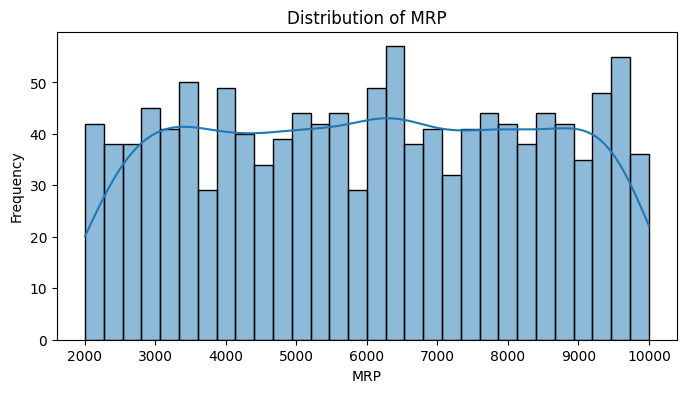

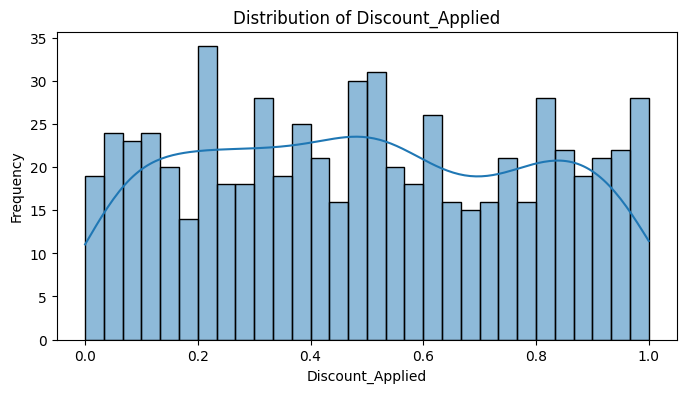

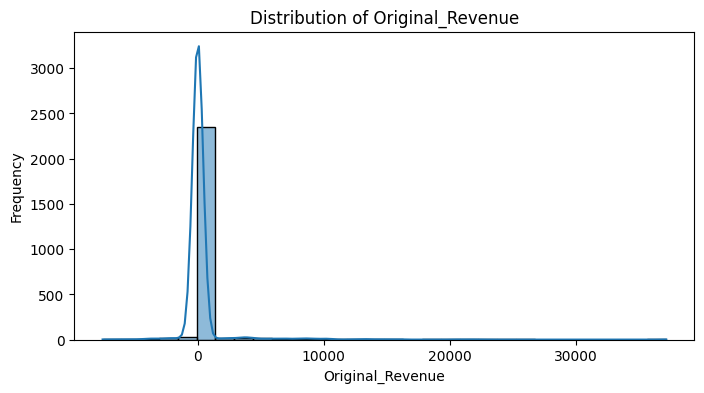

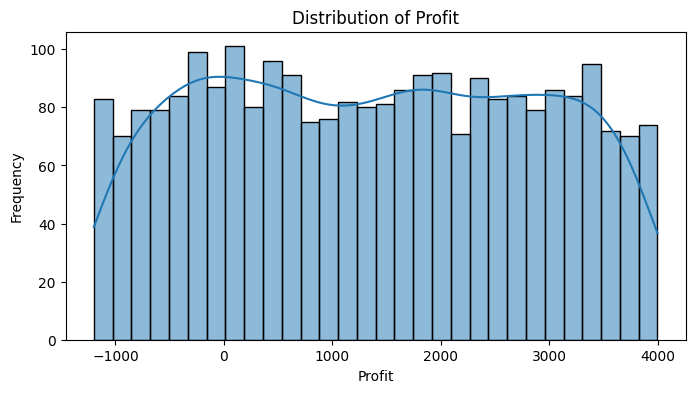

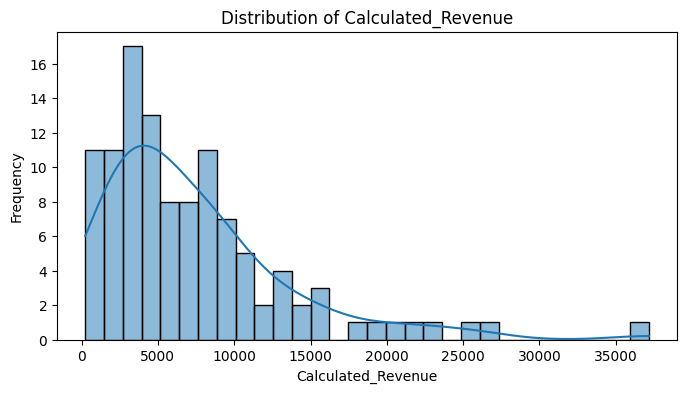

In [29]:
for col in numeric_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(nike[col].dropna(), bins=30, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

## Phase 2 – Univariate Analysis

### 2.1 Numerical Column Distributions

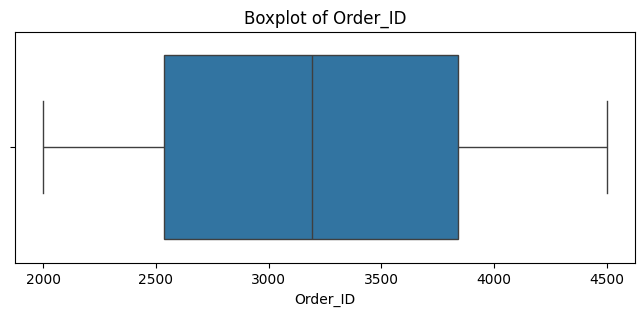

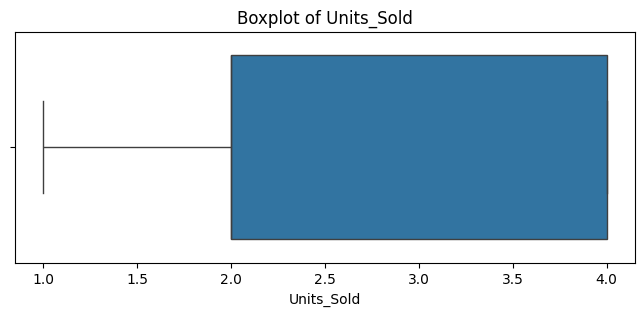

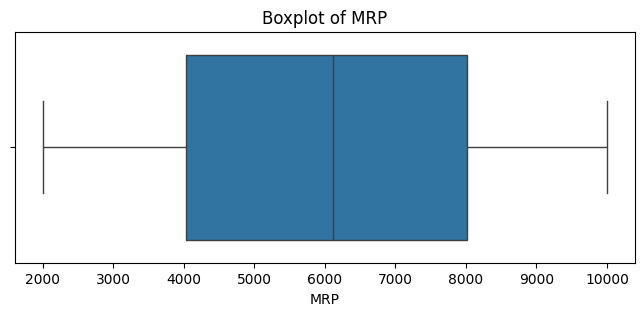

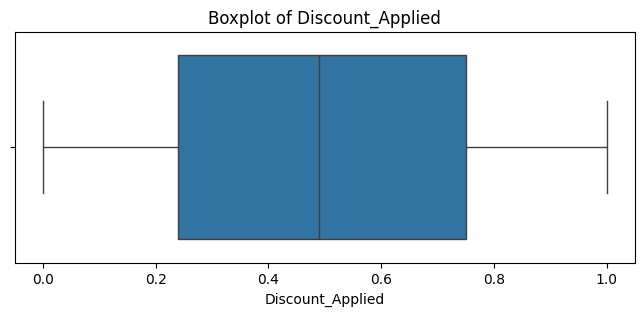

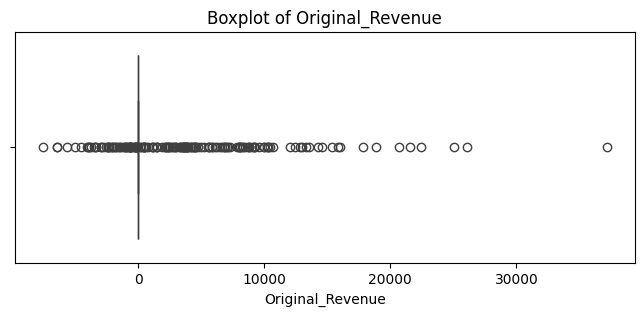

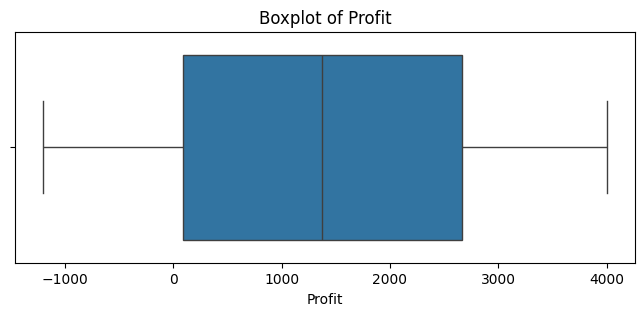

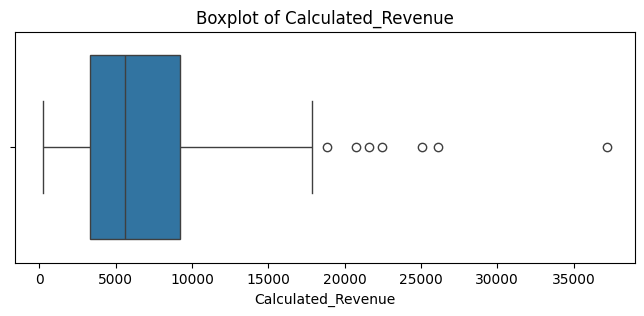

In [30]:
for col in numeric_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=nike[col])

    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)

    plt.show()

### 2.2 Numerical Outlier Inspection with Boxplots

In [31]:
categorical_cols = nike.select_dtypes(include=['object', 'category']).columns

print("Categorical Columns:")
print(categorical_cols.tolist())

Categorical Columns:
['Gender_Category', 'Product_Line', 'Product_Name', 'Sales_Channel', 'Region']


### 2.3 Identify Categorical Columns

In [32]:
for col in categorical_cols:

    print(f"\nTop 10 Values in {col}:")
    print(nike[col].value_counts().head(10))


Top 10 Values in Gender_Category:
Gender_Category
Kids     841
Men      840
Women    819
Name: count, dtype: int64

Top 10 Values in Product_Line:
Product_Line
Training      546
Basketball    507
Lifestyle     501
Running       474
Soccer        472
Name: count, dtype: int64

Top 10 Values in Product_Name:
Product_Name
Superrep Go         148
Lebron 20           144
Flex Trainer        141
Zoomx Invincible    140
Waffle One          137
React Infinity      134
Air Jordan          133
Phantom Gt          130
Blazer Mid          127
Free Rn             124
Name: count, dtype: int64

Top 10 Values in Sales_Channel:
Sales_Channel
Online    1255
Retail    1245
Name: count, dtype: int64

Top 10 Values in Region:
Region
Delhi        438
Bangalore    436
Mumbai       418
Kolkata      417
Hyderabad    403
Pune         388
Name: count, dtype: int64


### 2.4 Categorical Frequency Analysis

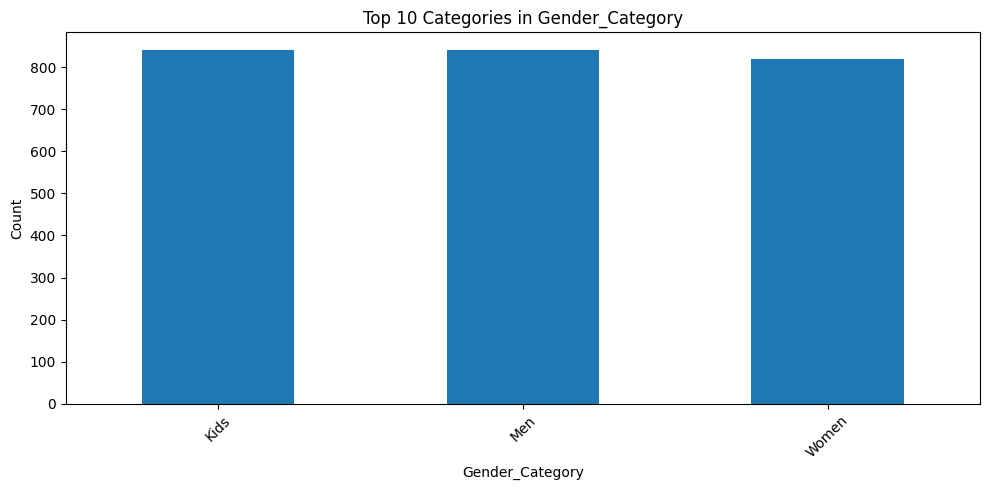

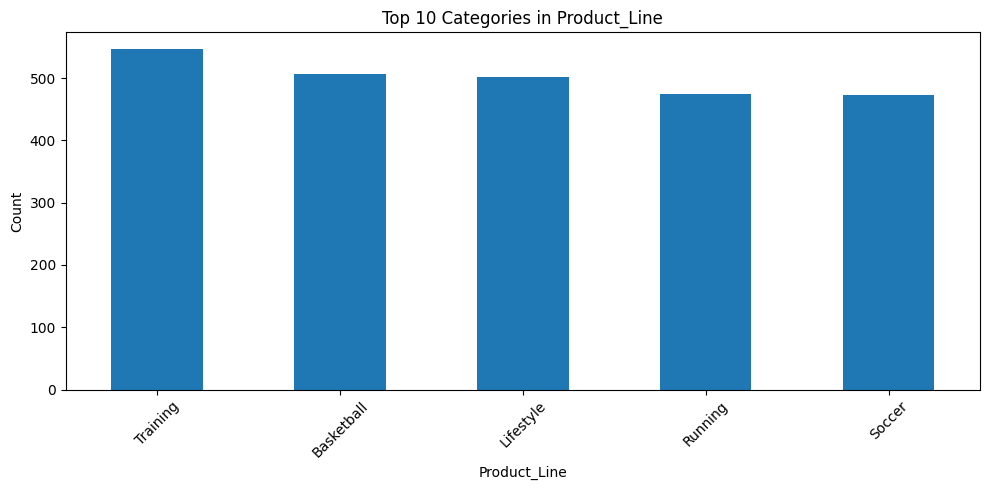

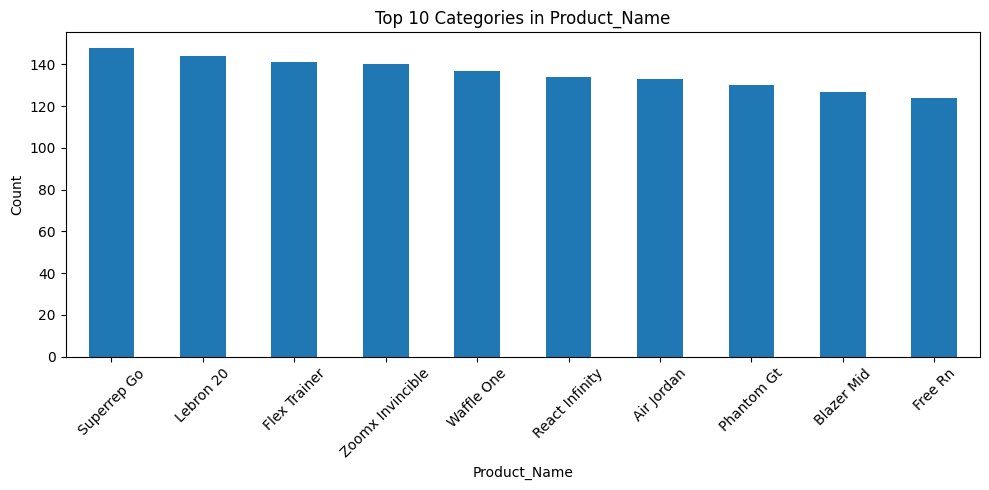

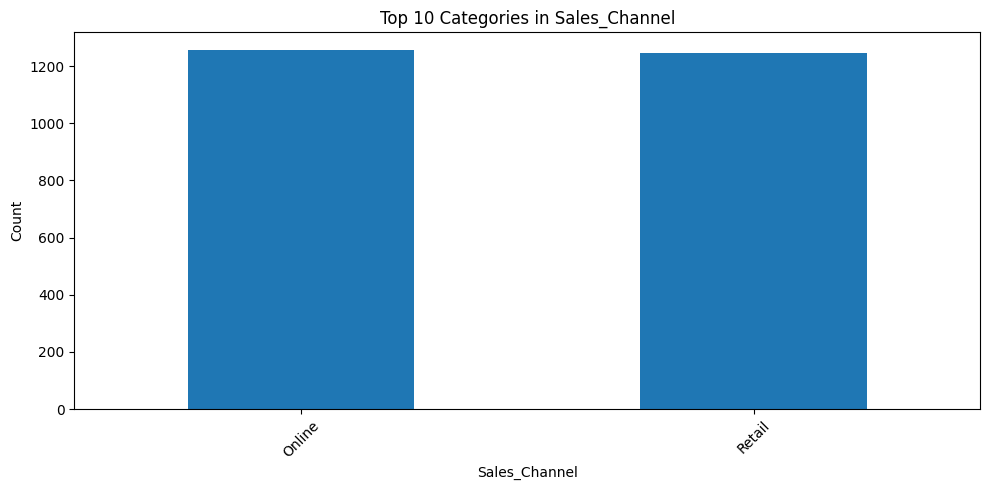

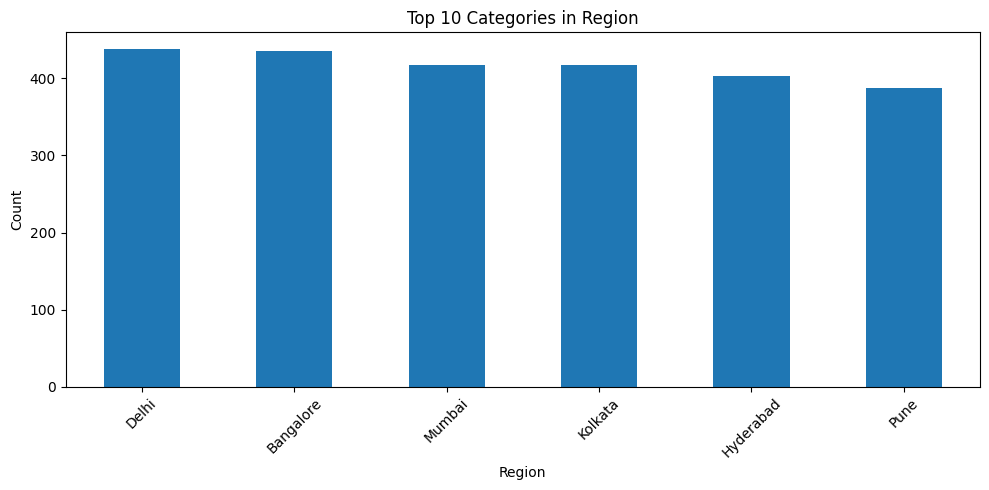

In [33]:
for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    nike[col].value_counts().head(10).plot(kind='bar')

    plt.title(f'Top 10 Categories in {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

### 2.5 Categorical Distribution Visualizations

In [34]:
print("Total Revenue:", nike['Calculated_Revenue'].sum())

print("Total Units Sold:", nike['Units_Sold'].sum())

print("Total Orders:", nike['Order_ID'].nunique())

print("Average Revenue:", nike['Calculated_Revenue'].mean())

print("Average Order Revenue:",
      nike.groupby('Order_ID')['Calculated_Revenue'].sum().mean())

Total Revenue: 801333.15
Total Units Sold: 2080.0
Total Orders: 2386
Average Revenue: 7284.846818181818
Average Order Revenue: 335.8479253981559


## Phase 3 – Sales Analysis

### 3.1 Overall Sales KPIs

In [35]:
product_sales = nike.groupby('Product_Line')['Calculated_Revenue'].sum().sort_values(ascending=False)

print(product_sales)

Product_Line
Training      211229.29
Lifestyle     179814.05
Basketball    168381.68
Soccer        147298.38
Running        94609.75
Name: Calculated_Revenue, dtype: float64


### 3.2 Revenue by Product Line

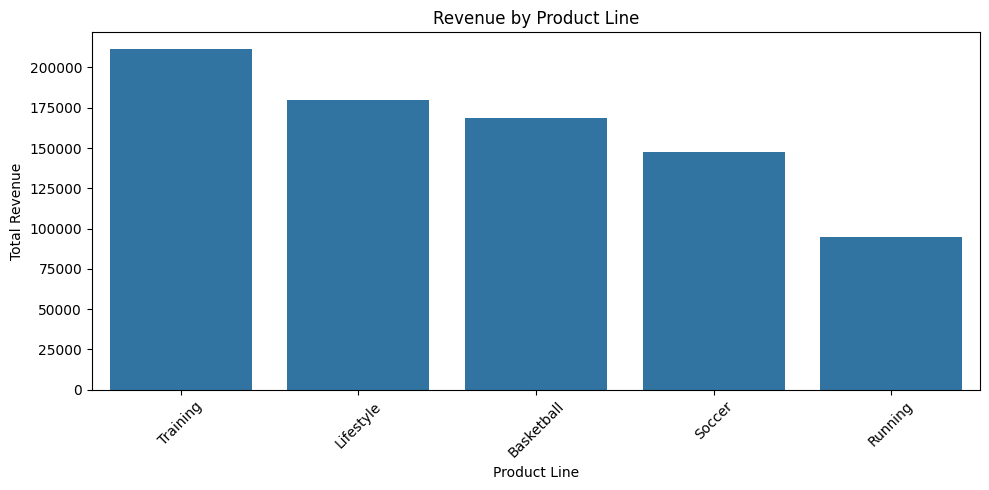

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(x=product_sales.index, y=product_sales.values)

plt.title('Revenue by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 3.3 Top 10 Products by Revenue

In [37]:
top_products = (
    nike.groupby('Product_Name')['Calculated_Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Product_Name
Flex Trainer        77067.95
Lebron 20           63676.17
Air Zoom            58144.30
Waffle One          56154.20
Zoom Freak          51500.51
Blazer Mid          50239.43
Superrep Go         49055.58
Zoomx Invincible    46404.46
Air Jordan          44854.03
Air Force 1         42612.14
Name: Calculated_Revenue, dtype: float64


### 3.4 Revenue Contribution by Gender Category

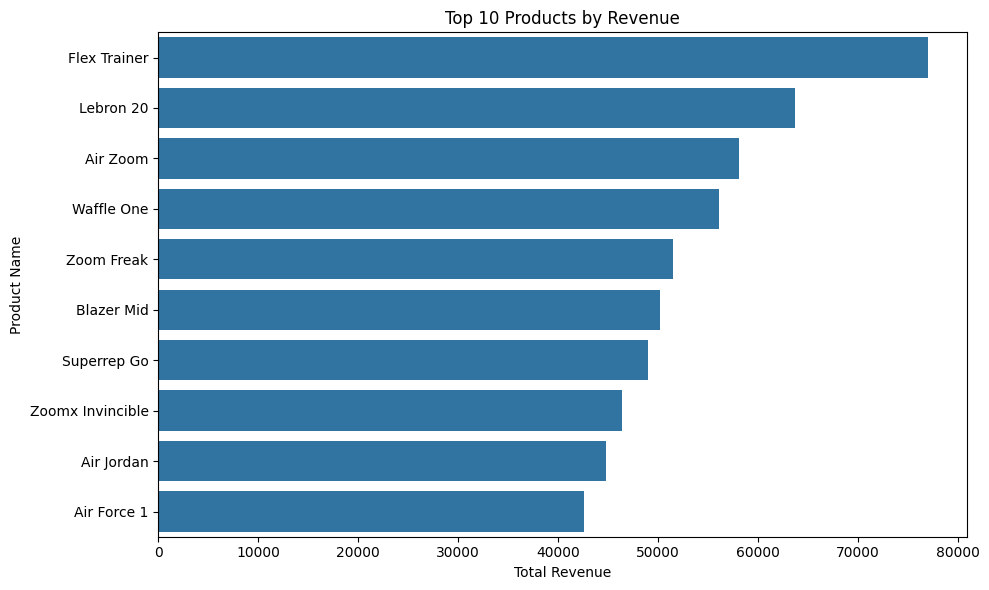

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

### 3.5 Sales Channel Analysis

In [39]:
gender_sales = (
    nike.groupby('Gender_Category')['Calculated_Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(gender_sales)

Gender_Category
Men      310701.43
Women    262365.43
Kids     228266.29
Name: Calculated_Revenue, dtype: float64


### 3.5.1 Revenue by Sales Channel

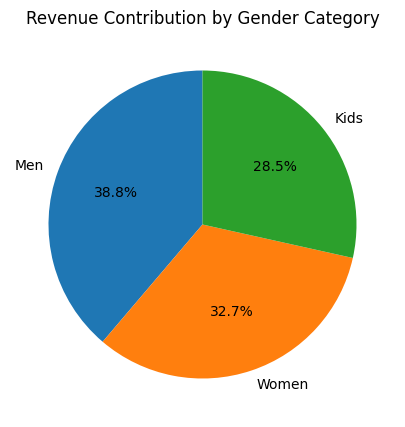

In [40]:
plt.figure(figsize=(7, 5))

plt.pie(
    gender_sales.values,
    labels=gender_sales.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Gender Category')
plt.show()

### 3.6 Regional Sales Analysis

In [41]:
channel_sales = nike.groupby('Sales_Channel').agg(
    Total_Revenue=('Calculated_Revenue', 'sum'),
    Total_Units=('Units_Sold', 'sum'),
    Total_Orders=('Order_ID', 'nunique')
)

print(channel_sales)

               Total_Revenue  Total_Units  Total_Orders
Sales_Channel                                          
Online             414364.49       1062.0          1212
Retail             386968.66       1018.0          1208


### 3.6.1 Revenue by Region

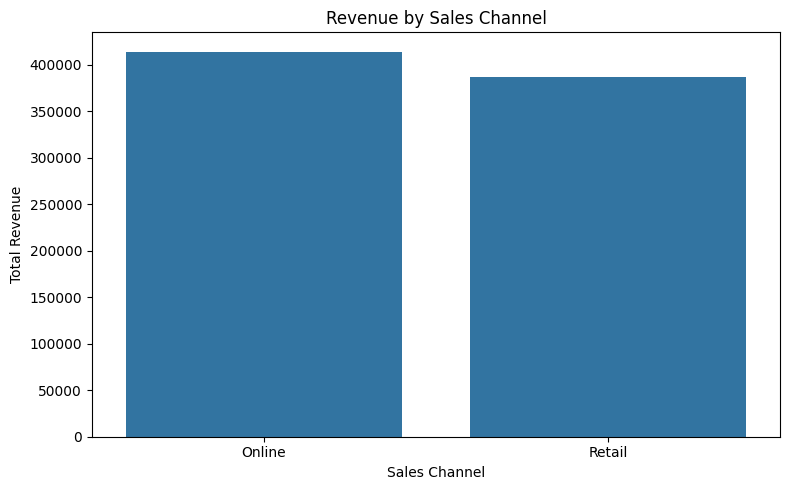

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=channel_sales.index,
    y=channel_sales['Total_Revenue']
)

plt.title('Revenue by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

## Phase 4 – Profit Analysis

> **Caution:** Profit values have not been independently reconciled to a documented accounting formula. Treat these as exploratory dataset values, not verified accounting profit. Negative values may be valid losses and should not be deleted automatically.

### 4.1 Overall Profit KPIs

In [43]:
region_sales = (
    nike.groupby('Region')['Calculated_Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(region_sales)

Region
Kolkata      178788.26
Hyderabad    140181.79
Bangalore    126966.81
Delhi        125131.77
Pune         123497.85
Mumbai       106766.67
Name: Calculated_Revenue, dtype: float64


### 4.1.1 Profitable, Loss-Making, and Zero-Profit Records

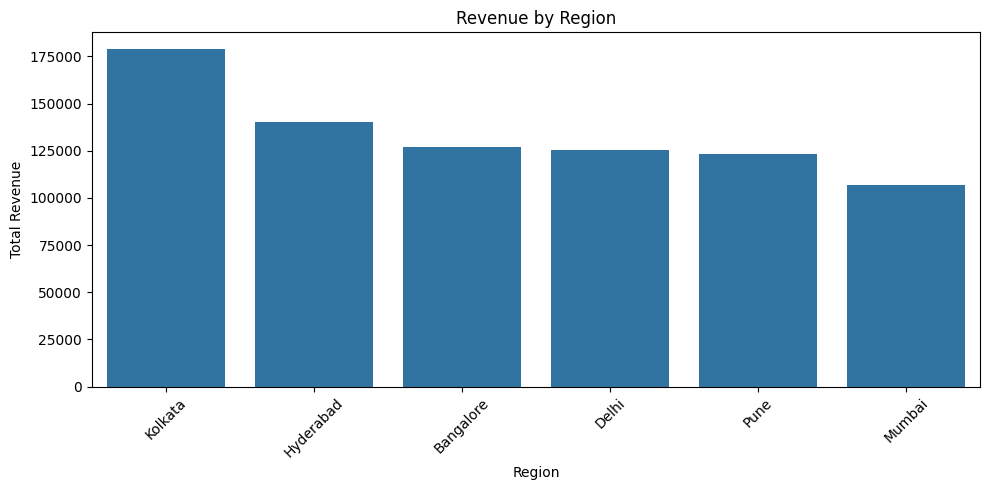

In [44]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title('Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.2 Profit Distribution

In [45]:
print("Total Profit:", nike['Profit'].sum())

print("Average Profit:", nike['Profit'].mean())

print("Maximum Profit:", nike['Profit'].max())

print("Minimum Profit:", nike['Profit'].min())

print("Median Profit:", nike['Profit'].median())

Total Profit: 3440032.12
Average Profit: 1376.012848
Maximum Profit: 3999.21
Minimum Profit: -1199.45
Median Profit: 1371.385


### 4.2.1 Profit Outlier Inspection

In [46]:
print("Profitable Records:", (nike['Profit'] > 0).sum())

print("Loss-Making Records:", (nike['Profit'] < 0).sum())

print("Zero Profit Records:", (nike['Profit'] == 0).sum())

Profitable Records: 1922
Loss-Making Records: 578
Zero Profit Records: 0


### 4.3 Profit by Product Line

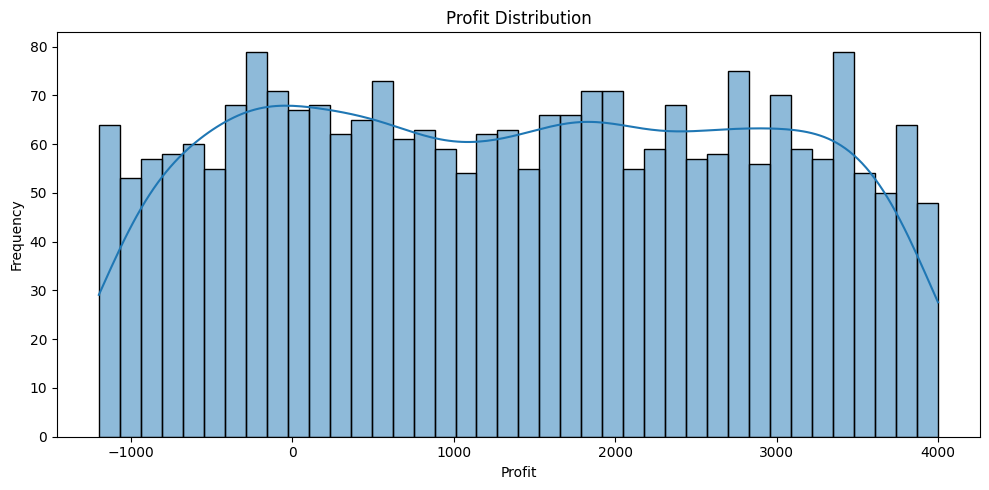

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(nike['Profit'], bins=40, kde=True)

plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 4.3.1 Visualize Profit by Product Line

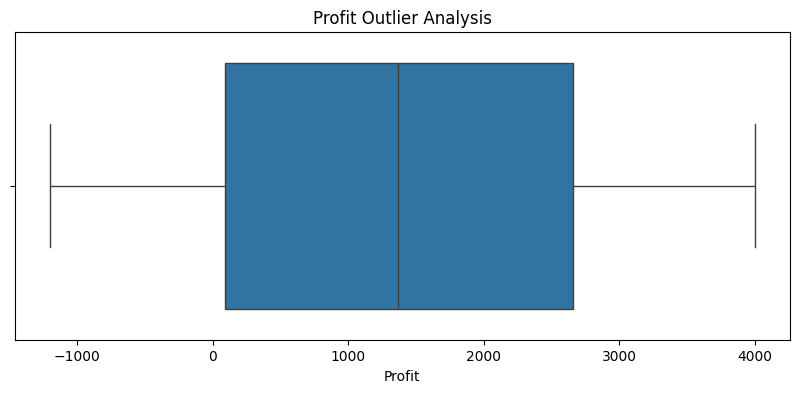

In [48]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=nike['Profit'])

plt.title('Profit Outlier Analysis')
plt.xlabel('Profit')

plt.show()

### 4.4 Top 10 Most Profitable Products

In [49]:
product_profit = (
    nike.groupby('Product_Line')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print(product_profit)

Product_Line
Training      737669.90
Lifestyle     694085.85
Basketball    676638.51
Soccer        673309.42
Running       658328.44
Name: Profit, dtype: float64


### 4.4.1 Visualize Top Profitable Products

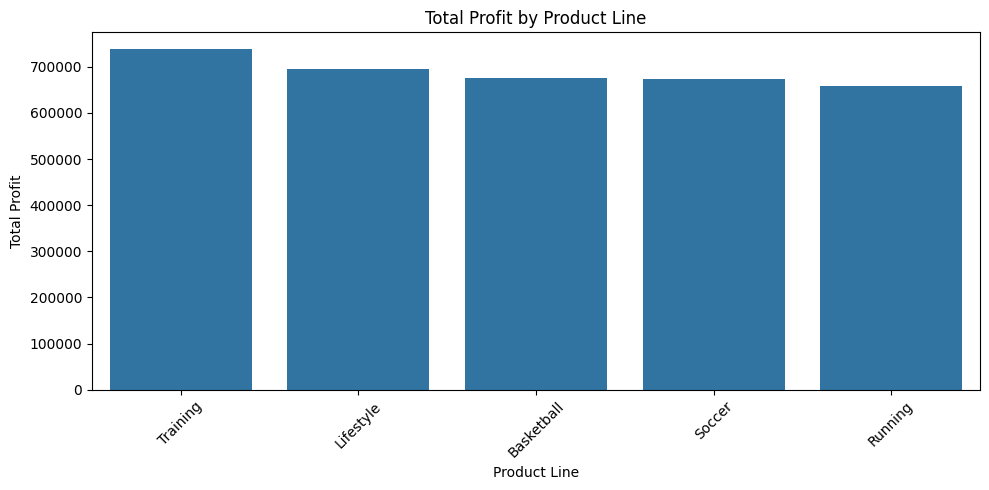

In [50]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_profit.index,
    y=product_profit.values
)

plt.title('Total Profit by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Profit')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.5 Loss-Making Products

In [51]:
top_profit_products = (
    nike.groupby('Product_Name')['Profit']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_profit_products)

Product_Name
Lebron 20             220287.24
Superrep Go           212719.79
Flex Trainer          199011.40
Phantom Gt            191718.51
React Infinity        189343.52
Blazer Mid            187250.68
Zoomx Invincible      186621.16
Free Rn               180060.46
Waffle One            178626.89
Mercurial Superfly    172642.58
Name: Profit, dtype: float64


### 4.5.1 Visualize Loss-Making Products

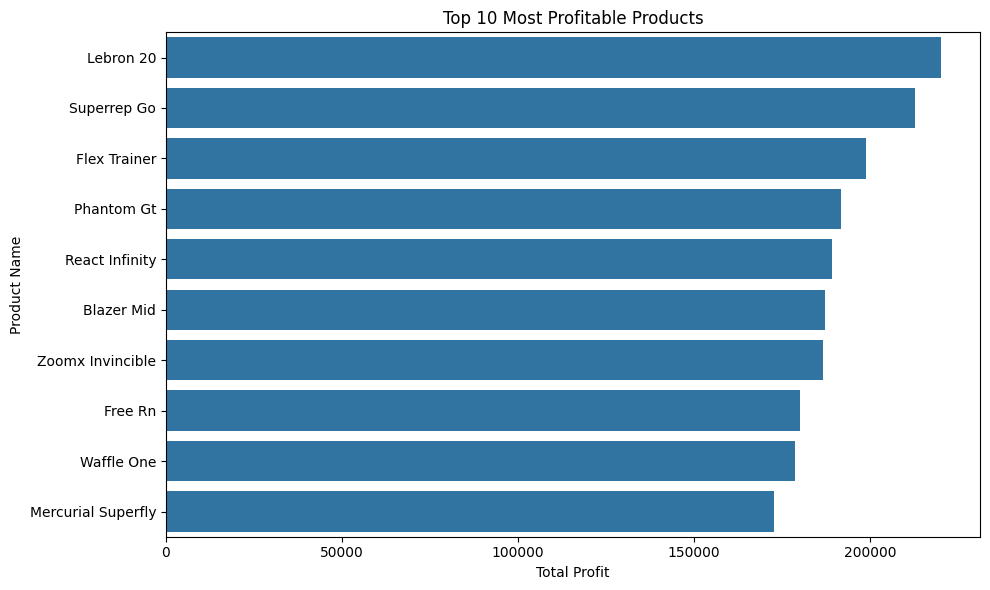

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_profit_products.values,
    y=top_profit_products.index
)

plt.title('Top 10 Most Profitable Products')
plt.xlabel('Total Profit')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [53]:
loss_products = (
    nike[nike['Profit'] < 0]
    .groupby('Product_Name')['Profit']
    .sum()
    .sort_values()
    .head(10)
)

print(loss_products)

Product_Name
Free Rn            -21277.95
Air Jordan         -20834.52
Waffle One         -20519.42
Tiempo Legend      -19274.30
Phantom Gt         -17798.90
Zoomx Invincible   -17216.73
Air Zoom           -16919.62
Blazer Mid         -16900.25
React Infinity     -16585.62
Kyrie Flytrap      -16542.66
Name: Profit, dtype: float64


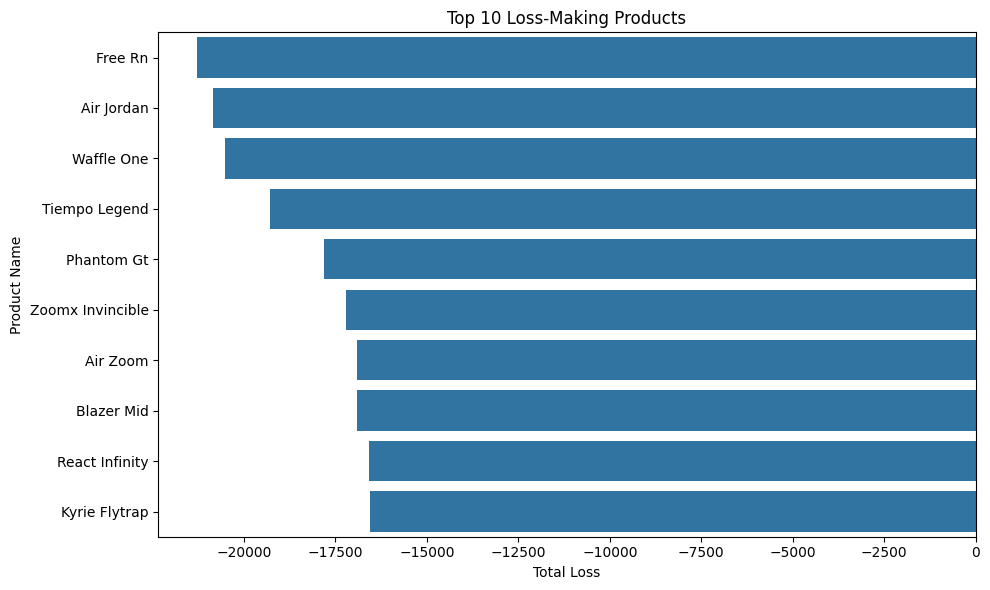

In [54]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=loss_products.values,
    y=loss_products.index
)

plt.title('Top 10 Loss-Making Products')
plt.xlabel('Total Loss')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

## Notebook Progress and Next Steps

**Included in this notebook:** data cleaning, validation, original/calculated revenue investigation, Phase 1 (dataset understanding), Phase 2 (univariate analysis), Phase 3 (sales analysis), and Phase 4 through Step 4.5 (loss-making products).

**Still to add:** Phase 4.6 (profit by region), Phase 4.7 (profit by sales channel), Phase 5 (product and category analysis), Phase 6 (discount analysis), Phase 7 (time-based analysis), Phase 8 (correlation and relationship analysis), and Phase 9 (business insights and recommendations).

After adding the remaining analyses, rerun the notebook from the beginning and save the final outputs.

### 4.5.2 Top 10 Most Profitable Products

The previous section identifies loss-making products. Here, we identify the products with the highest total profit.

**Business question:** Which individual products contribute the most profit?

In [55]:
top_profitable_products = (
    nike.groupby('Product_Name', dropna=True)['Profit']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_profitable_products)

Product_Name
Lebron 20             220287.24
Superrep Go           212719.79
Flex Trainer          199011.40
Phantom Gt            191718.51
React Infinity        189343.52
Blazer Mid            187250.68
Zoomx Invincible      186621.16
Free Rn               180060.46
Waffle One            178626.89
Mercurial Superfly    172642.58
Name: Profit, dtype: float64

### 4.5.3 Visualize Top 10 Most Profitable Products

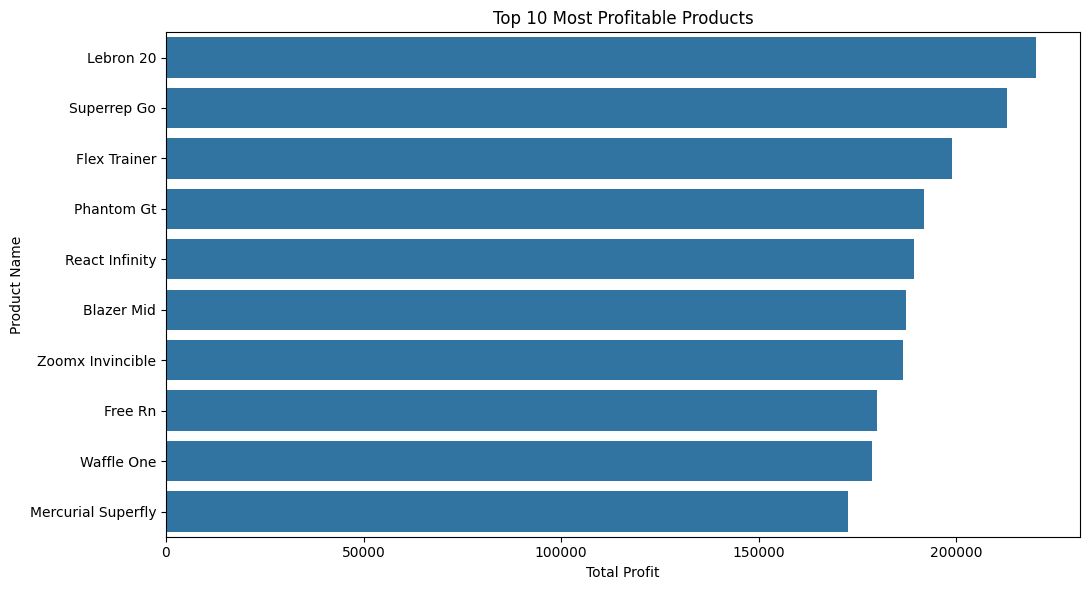

In [56]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_profitable_products.values,
    y=top_profitable_products.index
)

plt.title('Top 10 Most Profitable Products')
plt.xlabel('Total Profit')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

### 4.6 Profitability by Region

Compare the total profit generated in each region. This helps identify which regions contribute the most to overall profit.

In [57]:
region_profit = (
    nike.groupby('Region')['Profit']
    .sum()
    .sort_values(ascending=False)
)

display(region_profit)

Region
Bangalore    621948.74
Kolkata      602856.74
Delhi        587148.93
Mumbai       569568.34
Pune         533414.77
Hyderabad    525094.60
Name: Profit, dtype: float64

### 4.6.1 Visualize Profit by Region

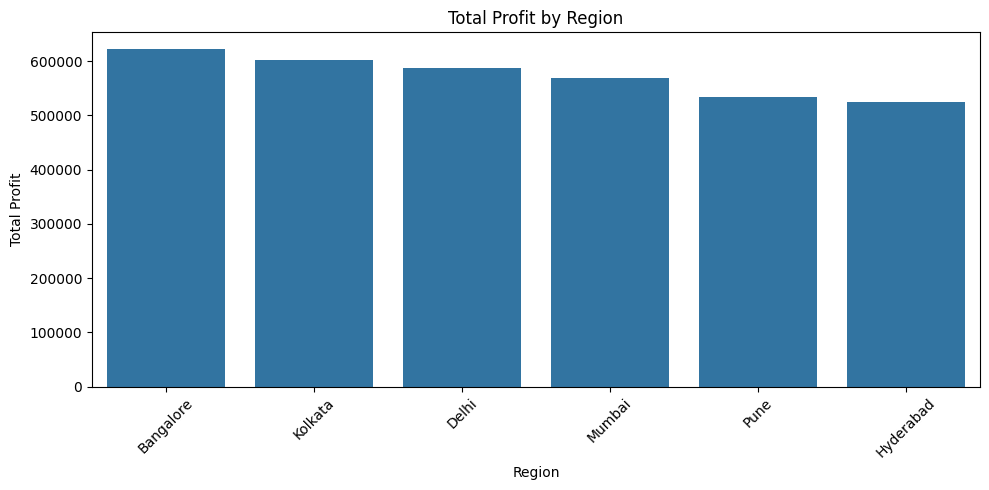

In [58]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=region_profit.index,
    y=region_profit.values
)

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.7 Profitability by Sales Channel

Compare profit across sales channels to understand which channel generates the highest total profit.

In [59]:
channel_profit = (
    nike.groupby('Sales_Channel')['Profit']
    .sum()
    .sort_values(ascending=False)
)

display(channel_profit)

Sales_Channel
Retail    1726844.77
Online    1713187.35
Name: Profit, dtype: float64

### 4.7.1 Visualize Profit by Sales Channel

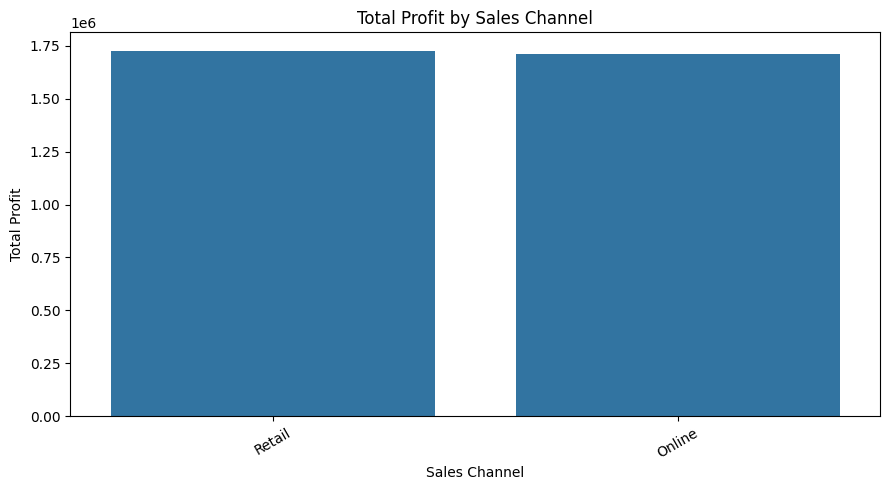

In [60]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_profit.index,
    y=channel_profit.values
)

plt.title('Total Profit by Sales Channel')
plt.xlabel('Sales Channel')
plt.ylabel('Total Profit')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 4.8 Profit Margin by Product Line

Profit margin is calculated as total profit divided by calculated revenue, multiplied by 100. It is useful for comparing profitability relative to revenue, rather than comparing profit totals alone.

Rows with zero or missing revenue are excluded from the margin calculation.

In [61]:
product_line_profitability = (
    nike.groupby('Product_Line')
    .agg(
        Total_Revenue=('Calculated_Revenue', 'sum'),
        Total_Profit=('Profit', 'sum'),
        Units_Sold=('Units_Sold', 'sum')
    )
)

product_line_profitability['Profit_Margin_Percent'] = np.where(
    product_line_profitability['Total_Revenue'] != 0,
    (product_line_profitability['Total_Profit'] /
     product_line_profitability['Total_Revenue']) * 100,
    np.nan
)

product_line_profitability = product_line_profitability.sort_values(
    'Profit_Margin_Percent',
    ascending=False
)

display(product_line_profitability)

,Total_Revenue,Total_Profit,Units_Sold,Profit_Margin_Percent
Product_Line,,,,
Running,94609.75,658328.44,337.0,695.835725
Soccer,147298.38,673309.42,430.0,457.105788
Basketball,168381.68,676638.51,392.0,401.848057
Lifestyle,179814.05,694085.85,460.0,386.002012
Training,211229.29,737669.90,461.0,349.227089


### 4.8.1 Visualize Profit Margin by Product Line

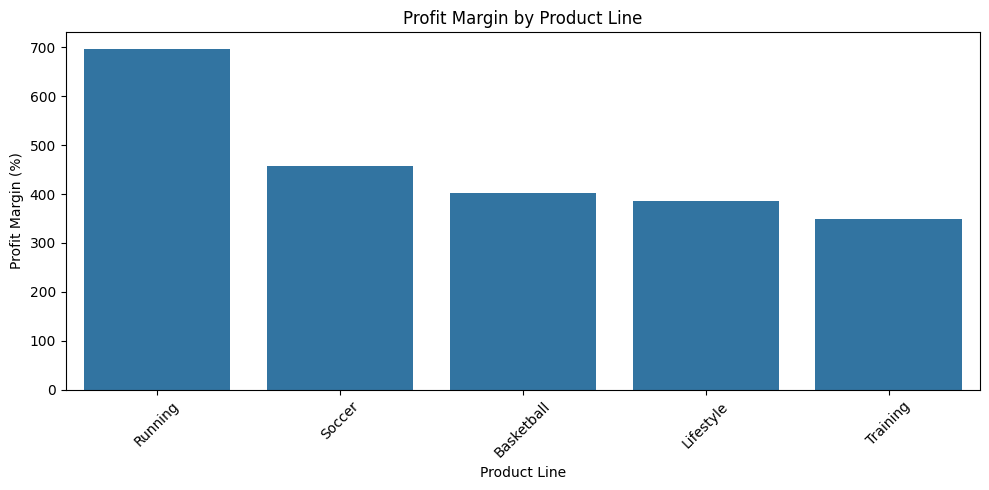

In [62]:
margin_plot_data = product_line_profitability['Profit_Margin_Percent'].dropna()

plt.figure(figsize=(10, 5))
sns.barplot(x=margin_plot_data.index, y=margin_plot_data.values)
plt.title('Profit Margin by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Profit Margin (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Phase 5 – Product & Category Analysis

This phase examines product demand and performance across product lines, individual products, and gender categories. It focuses on units sold and revenue, complementing the profitability analysis in Phase 4.

### 5.1 Units Sold by Product Line

**Business question:** Which product line sells the highest number of units?

In [63]:
units_by_product_line = (
    nike.groupby('Product_Line')['Units_Sold']
    .sum()
    .sort_values(ascending=False)
)

display(units_by_product_line)

Product_Line
Training      461.0
Lifestyle     460.0
Soccer        430.0
Basketball    392.0
Running       337.0
Name: Units_Sold, dtype: float64

### 5.1.1 Visualize Units Sold by Product Line

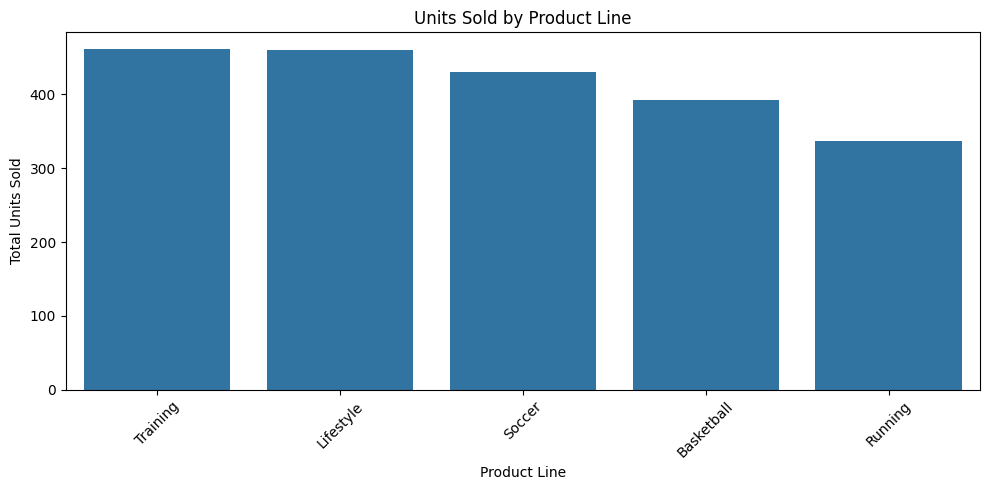

In [64]:
plt.figure(figsize=(10, 5))
sns.barplot(x=units_by_product_line.index, y=units_by_product_line.values)
plt.title('Units Sold by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.2 Top 10 Products by Units Sold

**Business question:** Which individual products have the highest sales volume?

In [65]:
top_products_by_units = (
    nike.groupby('Product_Name')['Units_Sold']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products_by_units)

Product_Name
Superrep Go         136.0
Blazer Mid          127.0
Flex Trainer        122.0
Zoom Freak          122.0
Premier Iii         121.0
Phantom Gt          119.0
Zoomx Invincible    118.0
Dunk Low            115.0
Waffle One          114.0
React Infinity      111.0
Name: Units_Sold, dtype: float64

### 5.2.1 Visualize Top 10 Products by Units Sold

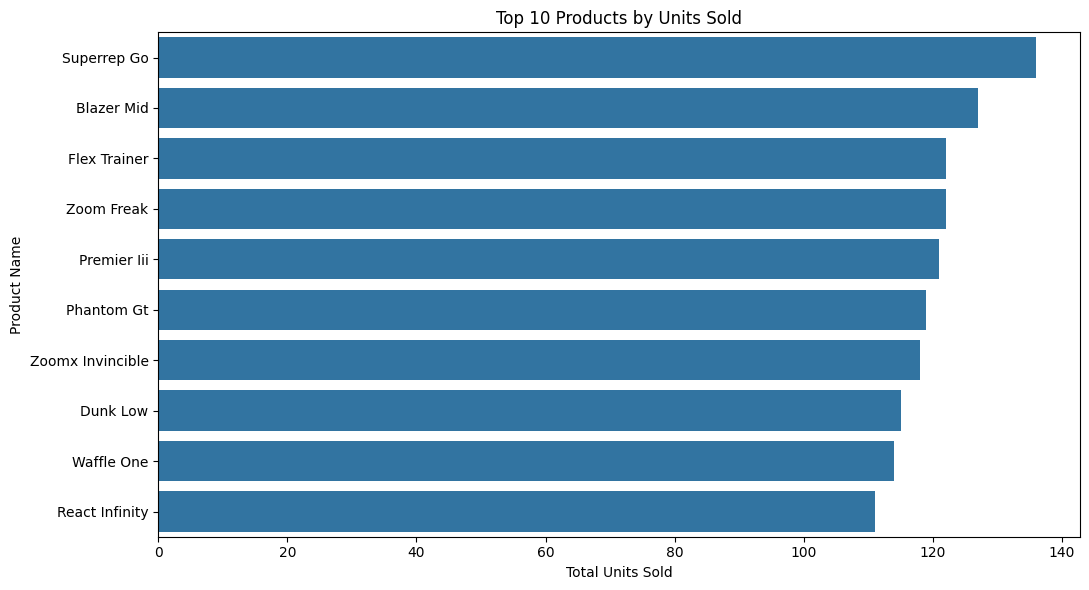

In [66]:
plt.figure(figsize=(11, 6))
sns.barplot(x=top_products_by_units.values, y=top_products_by_units.index)
plt.title('Top 10 Products by Units Sold')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

### 5.3 Average Selling Price by Product Line

Use calculated revenue divided by units sold as an approximate average realized selling price. Product lines with zero units are excluded.

In [67]:
avg_selling_price = (
    nike.groupby('Product_Line')
    .agg(
        Total_Revenue=('Calculated_Revenue', 'sum'),
        Total_Units=('Units_Sold', 'sum')
    )
)

avg_selling_price['Average_Selling_Price'] = np.where(
    avg_selling_price['Total_Units'] > 0,
    avg_selling_price['Total_Revenue'] / avg_selling_price['Total_Units'],
    np.nan
)

display(
    avg_selling_price.sort_values(
        'Average_Selling_Price',
        ascending=False
    )
)

,Total_Revenue,Total_Units,Average_Selling_Price
Product_Line,,,
Training,211229.29,461.0,458.198026
Basketball,168381.68,392.0,429.545102
Lifestyle,179814.05,460.0,390.900109
Soccer,147298.38,430.0,342.554372
Running,94609.75,337.0,280.741098


### 5.4 Product Line Performance by Gender Category

Compare revenue generated by each product line across gender categories.

In [68]:
gender_product_revenue = nike.pivot_table(
    index='Product_Line',
    columns='Gender_Category',
    values='Calculated_Revenue',
    aggfunc='sum',
    fill_value=0
)

display(gender_product_revenue)

Gender_Category,Kids,Men,Women
Product_Line,,,
Basketball,14140.52,78508.60,75732.56
Lifestyle,71713.02,62774.61,45326.42
Running,69973.50,18379.15,6257.10
Soccer,18393.86,59901.90,69002.62
Training,54045.39,91137.17,66046.73


### 5.4.1 Visualize Product Line Revenue by Gender Category

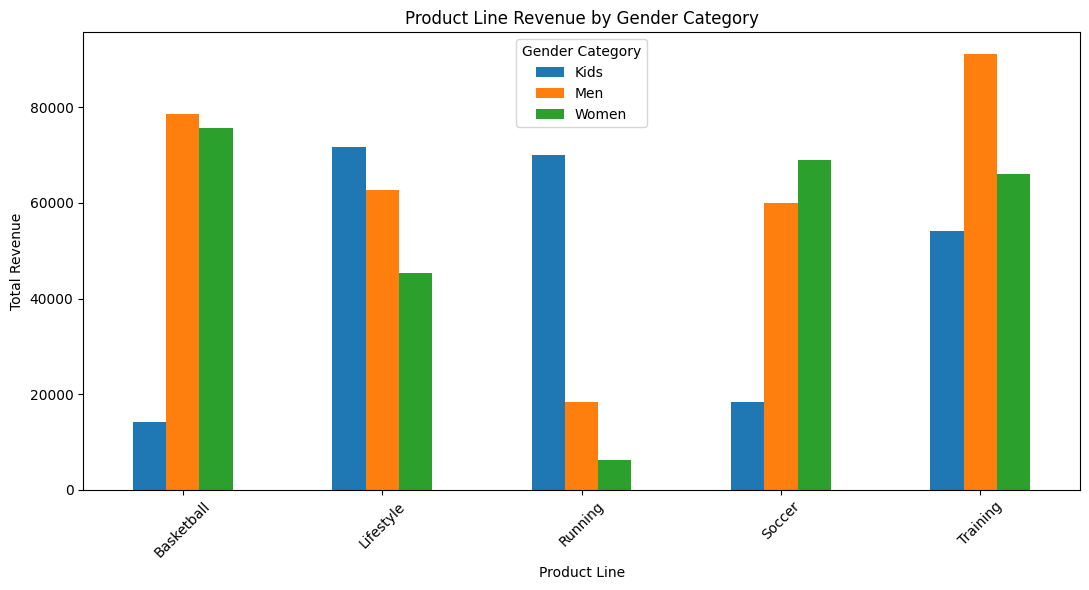

In [69]:
gender_product_revenue.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Product Line Revenue by Gender Category')
plt.xlabel('Product Line')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.legend(title='Gender Category')
plt.tight_layout()
plt.show()

### 5.5 Product Performance Summary

Create one summary table at product level containing units sold, revenue, and profit. This makes it easier to compare product demand and financial contribution in one place.

In [70]:
product_performance = (
    nike.groupby('Product_Name')
    .agg(
        Units_Sold=('Units_Sold', 'sum'),
        Total_Revenue=('Calculated_Revenue', 'sum'),
        Total_Profit=('Profit', 'sum')
    )
    .sort_values('Total_Revenue', ascending=False)
)

display(product_performance.head(15))

,Units_Sold,Total_Revenue,Total_Profit
Product_Name,,,
Flex Trainer,122.0,77067.95,199011.40
Lebron 20,100.0,63676.17,220287.24
Air Zoom,69.0,58144.30,133342.99
Waffle One,114.0,56154.20,178626.89
Zoom Freak,122.0,51500.51,158534.89
Blazer Mid,127.0,50239.43,187250.68
Superrep Go,136.0,49055.58,212719.79
Zoomx Invincible,118.0,46404.46,186621.16
Air Jordan,101.0,44854.03,158481.74
